In [2]:
!pip3 install opencv-python matplotlib -qqq

In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [99]:
image_path = "/Users/alexey/Downloads/test_image_2.jpeg"
image = cv2.imread(image_path, cv2.IMREAD_COLOR_RGB)
# image = image[:, image.shape[1] // 2:]
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

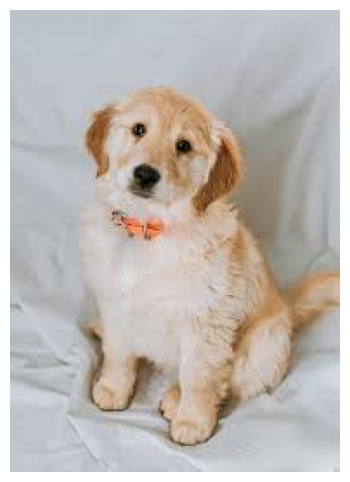

In [100]:
plt.figure(figsize=(8,6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [101]:
light_hist = np.zeros(256, dtype=np.int32)
r_hist = np.zeros(256, dtype=np.int32)
g_hist = np.zeros(256, dtype=np.int32)
b_hist = np.zeros(256, dtype=np.int32)

for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        light_hist[gray[i, j]] += 1

        r_hist[image[i, j, 0]] += 1
        g_hist[image[i, j, 1]] += 1
        b_hist[image[i, j, 2]] += 1

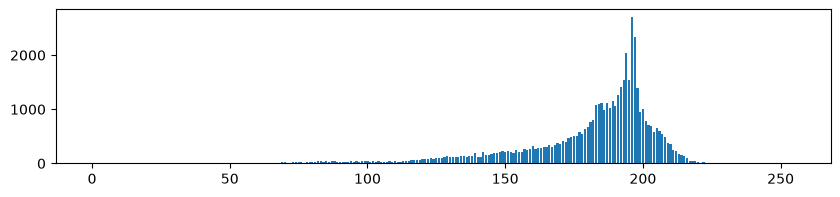

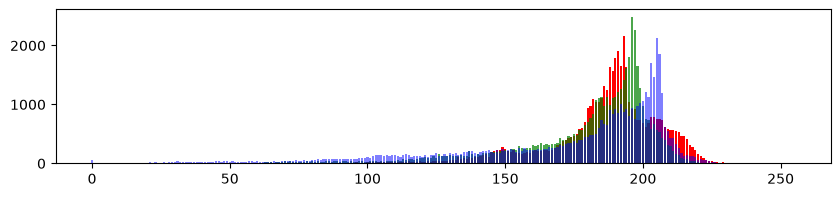

In [102]:
plt.figure(figsize=(10, 2))
plt.bar(list(range(256)), light_hist)

plt.figure(figsize=(10, 2))
plt.bar(list(range(256)), r_hist, color="red")
plt.bar(list(range(256)), g_hist, color="green", alpha=0.7)
plt.bar(list(range(256)), b_hist, color="blue", alpha=0.5)
plt.show()

In [103]:
thresh_low = 255 * 5 // 100
thresh_hight = 255 * 95 // 100

good_exp_thresh = 0.95

overexp_rate = 0
underexp_rate = 0
goodexp_rate = 0

for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        is_overexp_pixel = image[i, j, 0] == 255 and image[i, j, 1] == 255 and image[i, j, 2] == 255
        is_underexp_pixel = image[i, j, 0] == 0 and image[i, j, 1] == 0 and image[i, j, 2] == 0

        is_goodexp_r = thresh_low < image[i, j, 0] < thresh_hight
        is_goodexp_g = thresh_low < image[i, j, 1] < thresh_hight
        is_goodexp_b = thresh_low < image[i, j, 2] < thresh_hight

        is_good_pixel = is_goodexp_r and is_goodexp_g and is_goodexp_b

        overexp_rate += int(is_overexp_pixel)
        underexp_rate += int(is_underexp_pixel)
        goodexp_rate += int(is_good_pixel)

pixel_count = image.shape[0] * image.shape[1]
overexp_rate /= pixel_count
underexp_rate /= pixel_count
goodexp_rate /= pixel_count

print(f"Overexposed pixels rate: {overexp_rate:.5f}")
print(f"Underexposed pixels rate: {underexp_rate:.5f}")
print(f"Good exposed pixels rate: {goodexp_rate:.5f}")
print(f"Is good exp image: {goodexp_rate > good_exp_thresh}")

Overexposed pixels rate: 0.00000
Underexposed pixels rate: 0.00000
Good exposed pixels rate: 0.99705
Is good exp image: True


In [104]:
overexp_mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.bool_)

for i in range(image.shape[0]):
    for j in range(image.shape[1]):
        is_overgood_exp = gray[i, j] > thresh_hight
        overexp_mask[i, j] = is_overgood_exp

vis_image = image.copy()
vis_image[overexp_mask] = (vis_image[overexp_mask].astype(np.float16) * 0.4 + np.array([200.0, 50.0, 20.0]) * 0.6).astype(np.uint8)

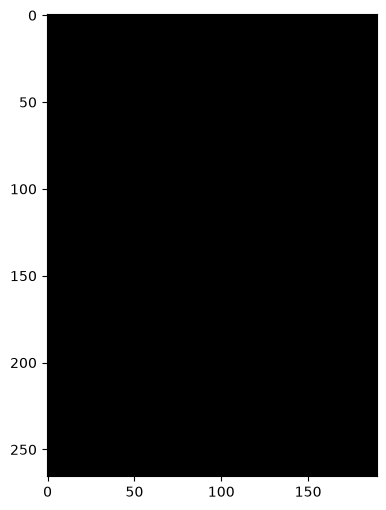

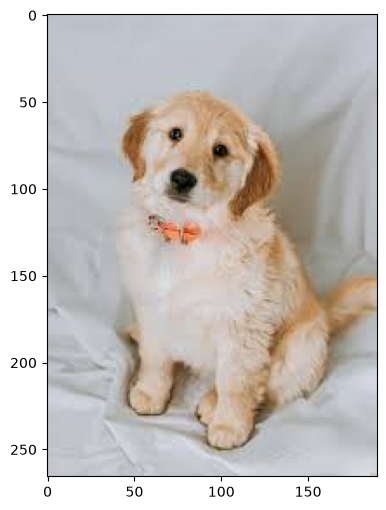

In [105]:
plt.figure(figsize=(8, 6))
plt.imshow(overexp_mask, "gray")
plt.figure(figsize=(8, 6))
plt.imshow(vis_image)
plt.show()

In [117]:
empty_image = np.zeros_like(image)
print(empty_image.shape, empty_image.dtype)

(266, 190, 3) uint8


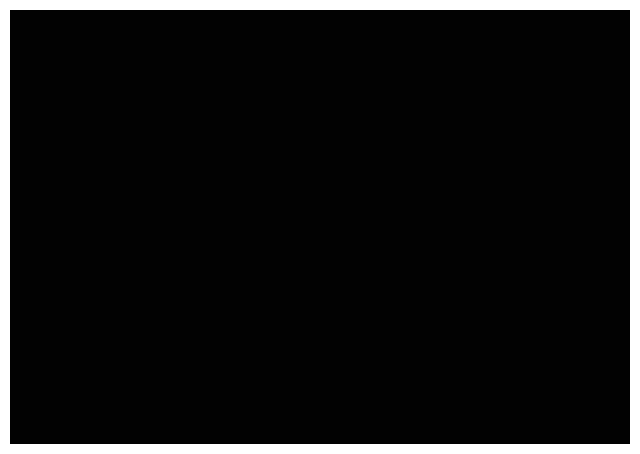

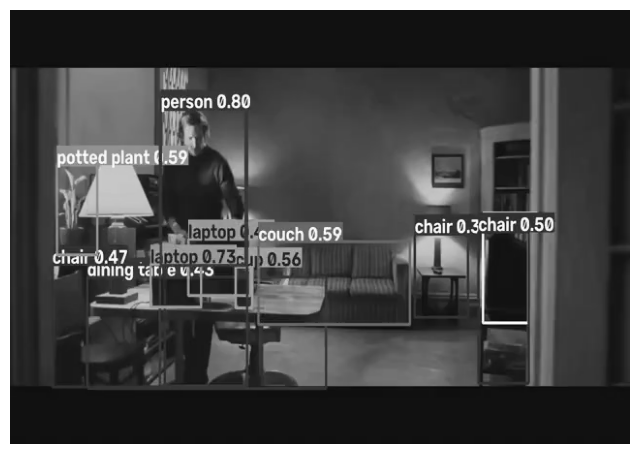

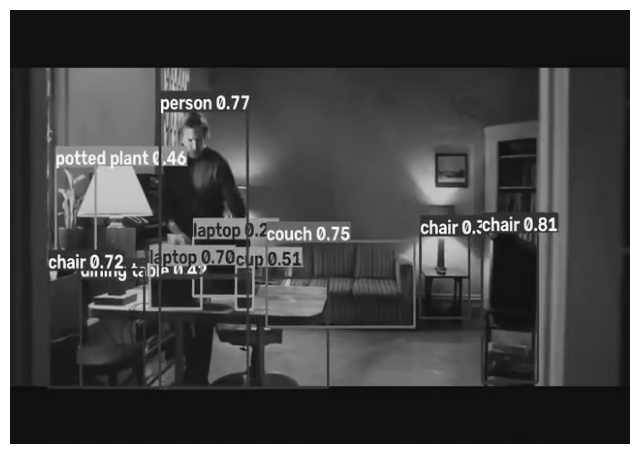

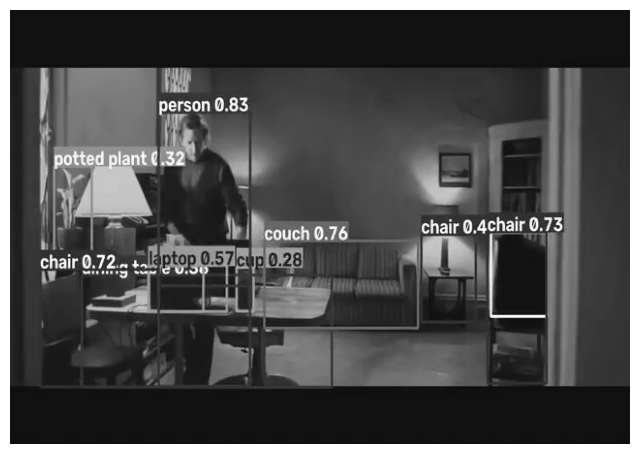

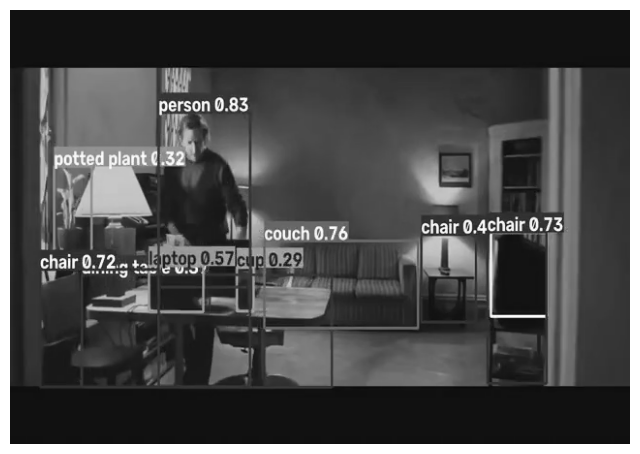

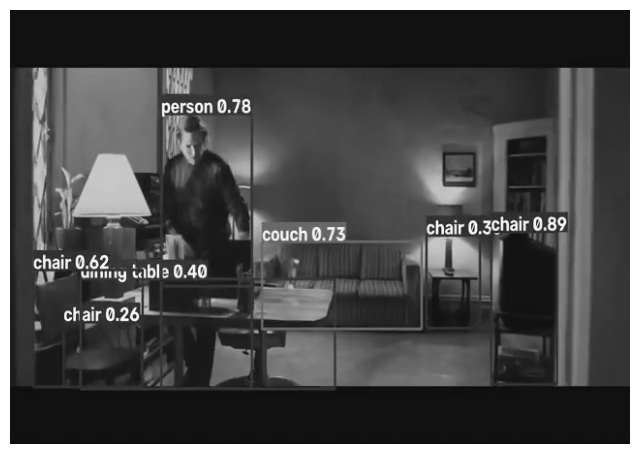

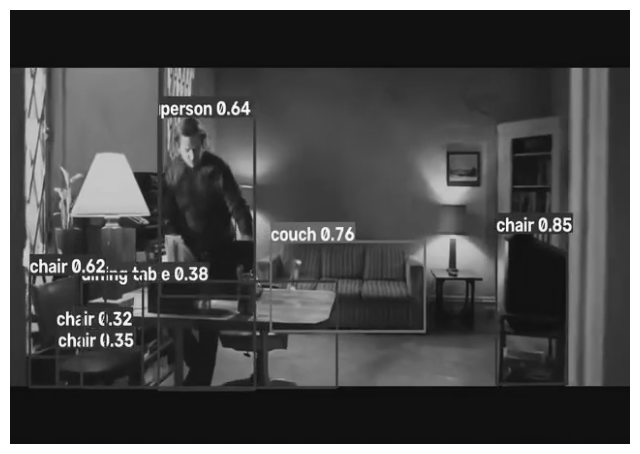

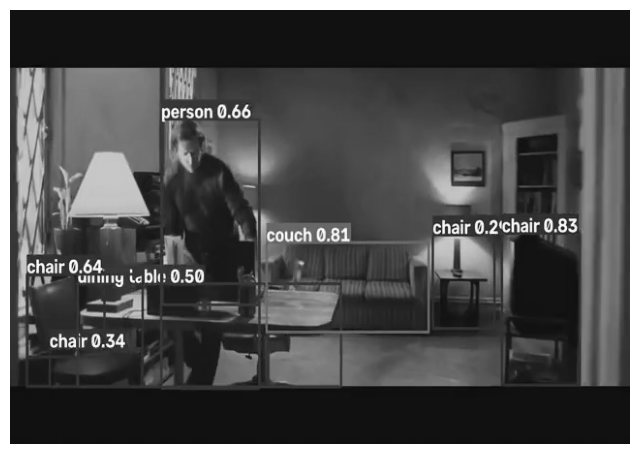

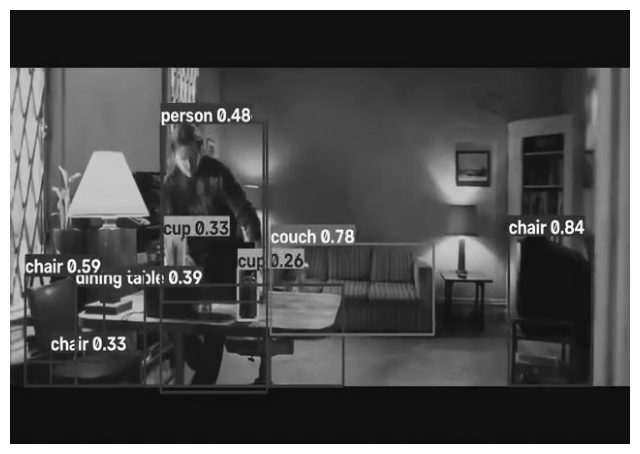

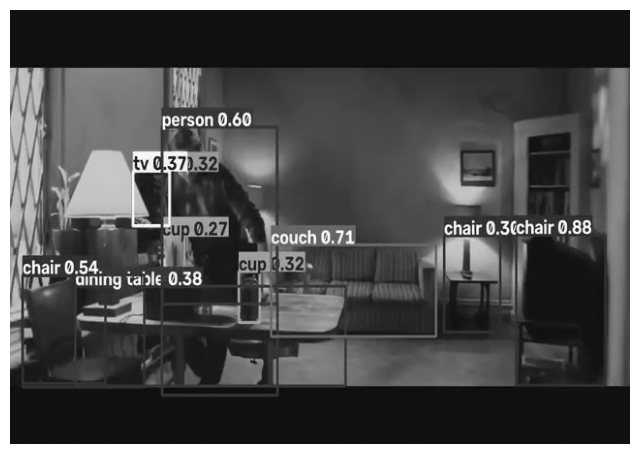

2030 2030
Video duration: 70.000000 sec


In [132]:
video_path = "/Users/alexey/Downloads/test_video.mp4"
gray_video_path = "/Users/alexey/Downloads/test_video_grayscale.mp4"

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frames_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

video_codec = cv2.VideoWriter_fourcc(*"mp4v")
video_writer = cv2.VideoWriter(gray_video_path, video_codec, fps, (w, h))

n_frame = 0

try:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray_frame = cv2.cvtColor(gray_frame, cv2.COLOR_GRAY2BGR)

        video_writer.write(gray_frame)

        if n_frame < 10:
            plt.figure(figsize=(8, 6))
            plt.imshow(gray_frame)
            plt.axis("off")

        n_frame += 1
finally:
    cap.release()
    video_writer.release()

plt.show()

print(n_frame, frames_count)
print(f"Video duration: {n_frame / fps:2f} sec")